In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
import matplotlib.pyplot as plt

data = pd.read_csv('../heart_statlog_cleveland_hungary_final.csv')

print("First 5 rows of data:")
data.head()

First 5 rows of data:


,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,ST_slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [ ]:
print("\nSummary Statistics:")
print(data.describe())
print("\nData Structure:")
print(data.info())


Summary Statistics:
               age          sex  chest_pain_type  resting_bp_s  cholesterol  \
count  1190.000000  1190.000000      1190.000000   1190.000000  1190.000000   
mean     53.720168     0.763866         3.232773    132.153782   210.363866   
std       9.358203     0.424884         0.935480     18.368823   101.420489   
min      28.000000     0.000000         1.000000      0.000000     0.000000   
25%      47.000000     1.000000         3.000000    120.000000   188.000000   
50%      54.000000     1.000000         4.000000    130.000000   229.000000   
75%      60.000000     1.000000         4.000000    140.000000   269.750000   
max      77.000000     1.000000         4.000000    200.000000   603.000000   

       fasting_blood_sugar  resting_ecg  max_heart_rate  exercise_angina  \
count          1190.000000  1190.000000     1190.000000      1190.000000   
mean              0.213445     0.698319      139.732773         0.387395   
std               0.409912     0.870359

In [ ]:
print(f"\nOriginal shape: {data.shape}")
duplicated_rows = data[data.duplicated()]
print(f"Duplicate rows found: {len(duplicated_rows)}")
data = data.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {data.shape}")


Original shape: (1190, 12)
Duplicate rows found: 272
Shape after removing duplicates: (918, 12)


In [ ]:
print("\nMissing values per column:")
print(data.isnull().sum())


Missing values per column:
age                    0
sex                    0
chest_pain_type        0
resting_bp_s           0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
ST_slope               0
target                 0
dtype: int64


In [ ]:
print("Missing values per column:")
print(data.isnull().sum())

# Numerical → mean
data.fillna(data.mean(numeric_only=True), inplace=True)

# Categorical → mode
data.fillna(data.mode().iloc[0], inplace=True)

Missing values per column:
age                    0
sex                    0
chest_pain_type        0
resting_bp_s           0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
ST_slope               0
target                 0
dtype: int64


,age,sex,chest_pain_type,resting_bp_s,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,ST_slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,1,110,264,0,0,132,0,1.2,2,1
914,68,1,4,144,193,1,0,141,0,3.4,2,1
915,57,1,4,130,131,0,0,115,1,1.2,2,1
916,57,0,2,130,236,0,2,174,0,0.0,2,1


In [ ]:
categorical_columns = [
    'sex',
    'chest_pain_type',
    'fasting_blood_sugar',
    'resting_ecg',
    'exercise_angina',
    'ST_slope'
]

data = pd.get_dummies(data, columns=categorical_columns, drop_first=True)

print("Shape after encoding:", data.shape)

Shape after encoding: (918, 17)


In [ ]:
data.head(5)

,age,resting_bp_s,cholesterol,max_heart_rate,oldpeak,target,sex_1,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,fasting_blood_sugar_1,resting_ecg_1,resting_ecg_2,exercise_angina_1,ST_slope_1,ST_slope_2,ST_slope_3
0,40,140,289,172,0.0,0,True,True,False,False,False,False,False,False,True,False,False
1,49,160,180,156,1.0,1,False,False,True,False,False,False,False,False,False,True,False
2,37,130,283,98,0.0,0,True,True,False,False,False,True,False,False,True,False,False
3,48,138,214,108,1.5,1,False,False,False,True,False,False,False,True,False,True,False
4,54,150,195,122,0.0,0,True,False,True,False,False,False,False,False,True,False,False


In [ ]:
large_scale_features = ['age', 'resting_bp_s', 'cholesterol', 'oldpeak']

for col in large_scale_features:
    
    mu = data[col].mean()         # Equation (2)
    sigma = data[col].std()       # Equation (3)
    
    data[col] = (data[col] - mu) / sigma   # Equation (1)

print("After Standardization:")
print(data[large_scale_features].head())

After Standardization:
        age  resting_bp_s  cholesterol   oldpeak
0 -1.432359      0.410685     0.824621 -0.831979
1 -0.478223      1.490940    -0.171867  0.105606
2 -1.750404     -0.129442     0.769768 -0.831979
3 -0.584238      0.302660     0.138964  0.574398
4  0.051853      0.950812    -0.034736 -0.831979


In [ ]:
numerical_columns = data.select_dtypes(include=['int64', 'float64']).columns
numerical_columns = numerical_columns.drop('target')

for col in numerical_columns:
    
    xmin = data[col].min()
    xmax = data[col].max()
    
    data[col] = (data[col] - xmin) / (xmax - xmin)

print("After Min-Max Normalization:")
data[numerical_columns].head()

After Min-Max Normalization:


,age,resting_bp_s,cholesterol,max_heart_rate,oldpeak
0,0.244898,0.70,0.479270,0.788732,0.295455
1,0.428571,0.80,0.298507,0.676056,0.409091
2,0.183673,0.65,0.469320,0.267606,0.295455
3,0.408163,0.69,0.354892,0.338028,0.465909
4,0.530612,0.75,0.323383,0.436620,0.295455


In [ ]:
data.head()

,age,resting_bp_s,cholesterol,max_heart_rate,oldpeak,target,sex_1,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,fasting_blood_sugar_1,resting_ecg_1,resting_ecg_2,exercise_angina_1,ST_slope_1,ST_slope_2,ST_slope_3
0,0.244898,0.70,0.479270,0.788732,0.295455,0,True,True,False,False,False,False,False,False,True,False,False
1,0.428571,0.80,0.298507,0.676056,0.409091,1,False,False,True,False,False,False,False,False,False,True,False
2,0.183673,0.65,0.469320,0.267606,0.295455,0,True,True,False,False,False,True,False,False,True,False,False
3,0.408163,0.69,0.354892,0.338028,0.465909,1,False,False,False,True,False,False,False,True,False,True,False
4,0.530612,0.75,0.323383,0.436620,0.295455,0,True,False,True,False,False,False,False,False,True,False,False


In [ ]:
X = data.drop("target", axis=1)
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (734, 16)
Test shape: (184, 16)


In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

import numpy as np

regl_model = LogisticRegression(
    class_weight='balanced',
    max_iter=20,
    random_state=42,
    solver='liblinear',
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(regl_model, X_train, y_train, cv=cv, scoring='accuracy')

print(f"CV Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

regl_model.fit(X_train, y_train)
y_pred = regl_model.predict(X_test)
y_proba = regl_model.predict_proba(X_test)[:, 1]

CV Scores: [0.83673469 0.78231293 0.84353741 0.88435374 0.85616438]
Mean CV Accuracy: 84.06% (+/- 3.34%)


In [ ]:
from sklearn.model_selection import GridSearchCV
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

param_grid_1 = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],       
    'solver': ['liblinear', 'saga'] 
}

grid_1 = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_1,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_1.fit(X_train, y_train)

print("Best Parameters (Recommended Search):")
print(grid_1.best_params_)
print("Best CV Accuracy:", grid_1.best_score_)

Best Parameters (Recommended Search):
{'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Best CV Accuracy: 0.861218067382451


C:\Users\Mohammad\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Mohammad\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


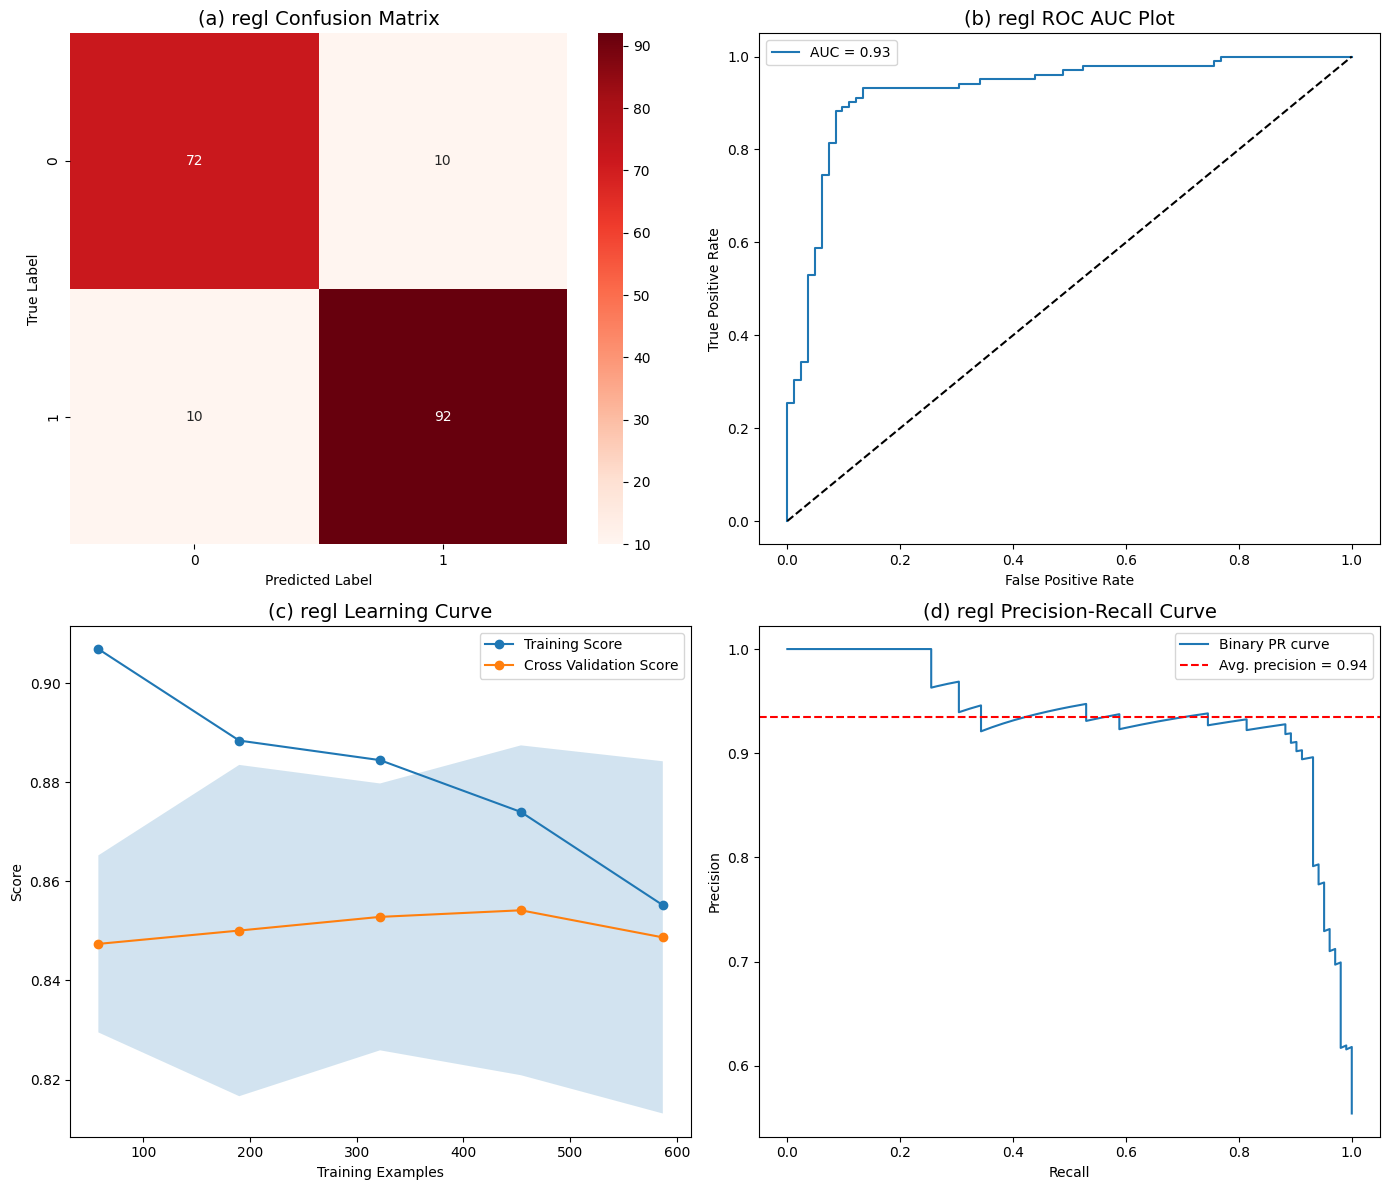

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import learning_curve

# Predictions
y_pred = regl_model.predict(X_test)
y_proba = regl_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    ax=axes[0, 0]
)

axes[0, 0].set_title("(a) regl Confusion Matrix", fontsize=14)
axes[0, 0].set_xlabel("Predicted Label")
axes[0, 0].set_ylabel("True Label")
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

axes[0, 1].plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
axes[0, 1].plot([0, 1], [0, 1], 'k--')
axes[0, 1].set_title("(b) regl ROC AUC Plot", fontsize=14)
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend()

# Learning Curve
train_sizes, train_scores, val_scores = learning_curve(
    regl_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

axes[1, 0].plot(train_sizes, train_mean, 'o-', label="Training Score")
axes[1, 0].plot(train_sizes, val_mean, 'o-', label="Cross Validation Score")
axes[1, 0].fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

axes[1, 0].set_title("(c) regl Learning Curve", fontsize=14)
axes[1, 0].set_xlabel("Training Examples")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_proba)
avg_precision = average_precision_score(y_test, y_proba)

axes[1, 1].plot(recall, precision, label="Binary PR curve")
axes[1, 1].axhline(y=avg_precision, linestyle='--', color='r',
                   label=f"Avg. precision = {avg_precision:.2f}")

axes[1, 1].set_title("(d) regl Precision-Recall Curve", fontsize=14)
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

precision_val = precision_score(y_test, y_pred)
recall_val = recall_score(y_test, y_pred)
f1_val = f1_score(y_test, y_pred)
accuracy_val = accuracy_score(y_test, y_pred)

print(f"Precision: {precision_val*100:.2f}%")
print(f"Recall: {recall_val*100:.2f}%")
print(f"F1 Score: {f1_val*100:.2f}%")
print(f"Accuracy: {accuracy_val*100:.2f}%")
print(f"Accuracy Loss: {(1-accuracy_val)*100:.2f}%")

Precision: 90.20%
Recall: 90.20%
F1 Score: 90.20%
Accuracy: 89.13%
Accuracy Loss: 10.87%


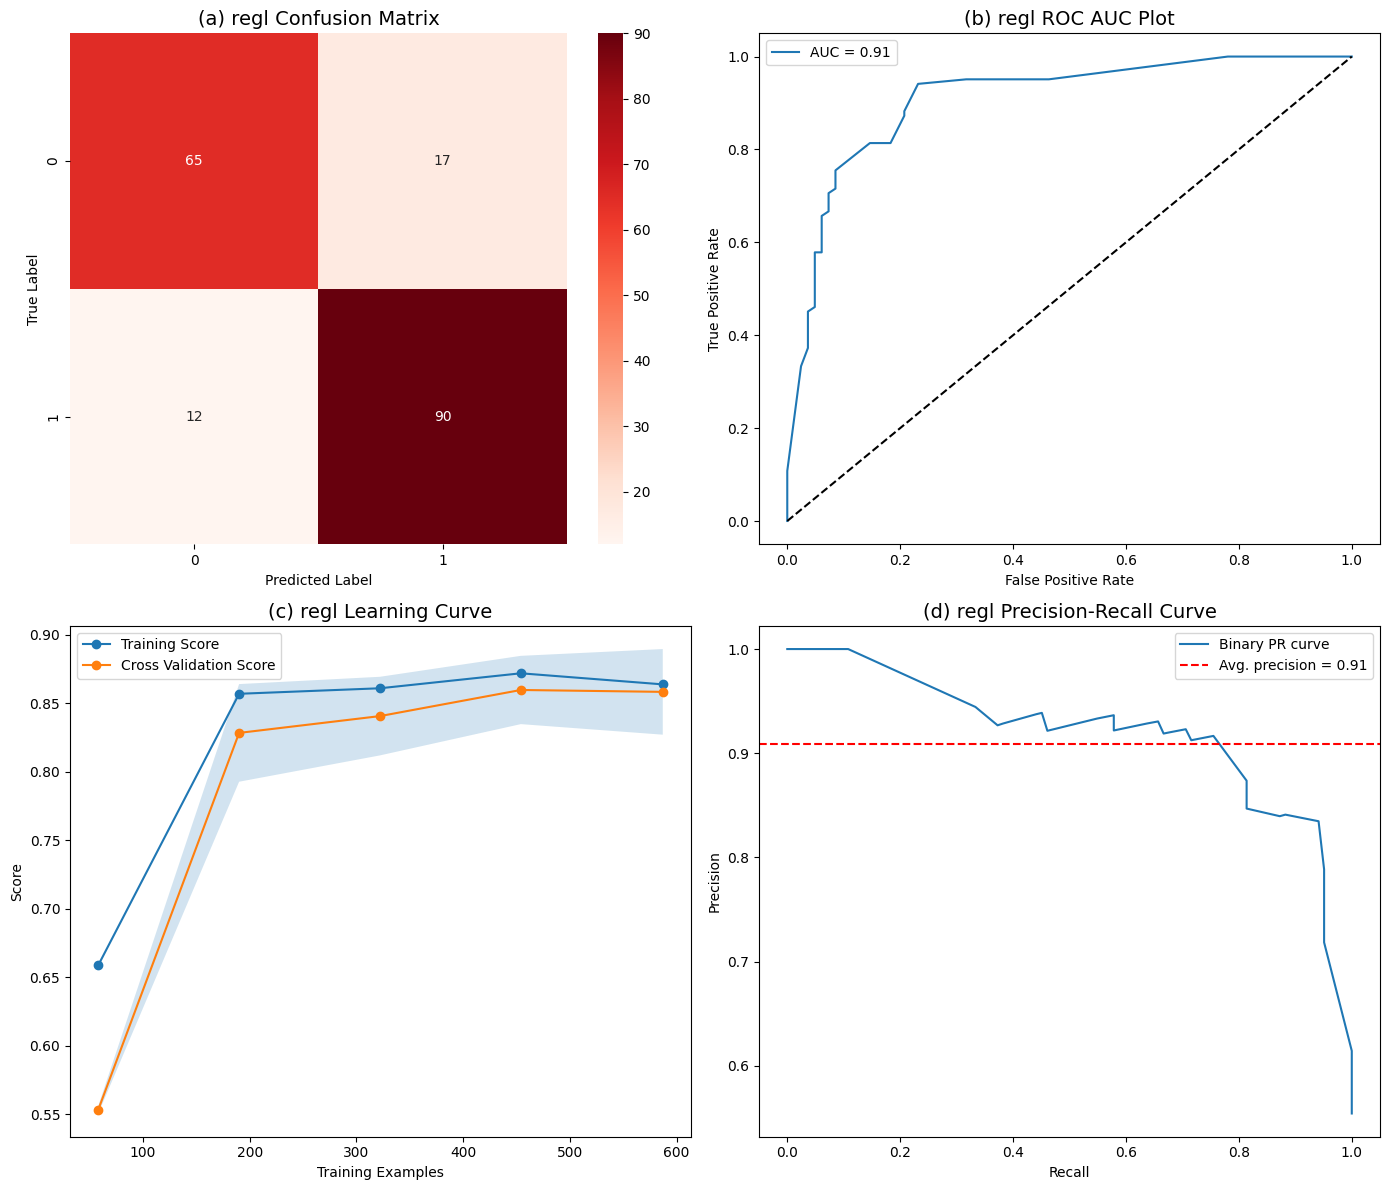

In [ ]:
import numpy as np
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import learning_curve

# Predictions
y_pred = grid_1.best_estimator_.predict(X_test)
y_proba = grid_1.best_estimator_.predict_proba(X_test)[:, 1]

# Create 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# ==========================================================
# (a) Confusion Matrix
# ==========================================================
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    ax=axes[0, 0]
)

axes[0, 0].set_title("(a) regl Confusion Matrix", fontsize=14)
axes[0, 0].set_xlabel("Predicted Label")
axes[0, 0].set_ylabel("True Label")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

axes[0, 1].plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
axes[0, 1].plot([0, 1], [0, 1], 'k--')
axes[0, 1].set_title("(b) regl ROC AUC Plot", fontsize=14)
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend()

# Learning Curve
train_sizes, train_scores, val_scores = learning_curve(
    grid_1.best_estimator_,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

axes[1, 0].plot(train_sizes, train_mean, 'o-', label="Training Score")
axes[1, 0].plot(train_sizes, val_mean, 'o-', label="Cross Validation Score")
axes[1, 0].fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

axes[1, 0].set_title("(c) regl Learning Curve", fontsize=14)
axes[1, 0].set_xlabel("Training Examples")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_proba)
avg_precision = average_precision_score(y_test, y_proba)

axes[1, 1].plot(recall, precision, label="Binary PR curve")
axes[1, 1].axhline(y=avg_precision, linestyle='--', color='r',
                   label=f"Avg. precision = {avg_precision:.2f}")

axes[1, 1].set_title("(d) regl Precision-Recall Curve", fontsize=14)
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

precision_val = precision_score(y_test, y_pred)
recall_val = recall_score(y_test, y_pred)
f1_val = f1_score(y_test, y_pred)
accuracy_val = accuracy_score(y_test, y_pred)

print(f"Precision: {precision_val*100:.2f}%")
print(f"Recall: {recall_val*100:.2f}%")
print(f"F1 Score: {f1_val*100:.2f}%")
print(f"Accuracy: {accuracy_val*100:.2f}%")
print(f"Accuracy Loss: {(1-accuracy_val)*100:.2f}%")

Precision: 84.11%
Recall: 88.24%
F1 Score: 86.12%
Accuracy: 84.24%
Accuracy Loss: 15.76%
